# Práctica 1: Uso de embeddings preentrenados

Adaptación del modelo LSTM del Notebook 13 (clasificación de AG_NEWS) para usar embeddings GloVe preentrenados, y comparación con embeddings aleatorios y entre distintos tamaños (50d, 100d, 200d y 300d).

## 1. Instalación

In [8]:
%pip install huggingface_hub

Note: you may need to restart the kernel to use updated packages.


## 2. Datos y vocabulario

In [9]:
import re, csv, os, time, io, zipfile, urllib.request
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

# AG_NEWS: CSV originales (columnas: clase 1-4, título, descripción)
BASE_URL = "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/"

def load_ag_news(split):
    path = f"ag_news_{split}.csv"
    if not os.path.exists(path):
        urllib.request.urlretrieve(BASE_URL + f"{split}.csv", path)
    data = []
    with open(path, encoding="utf-8") as f:
        for label, title, desc in csv.reader(f):
            text = (title + " " + desc).replace("\\", " ")
            data.append((int(label) - 1, text))   # etiquetas 0-3
    return data

train_raw = load_ag_news("train")
test_raw = load_ag_news("test")
print(len(train_raw), "noticias de entrenamiento,", len(test_raw), "de test")

# Tokenizador sencillo: minúsculas, palabras y signos de puntuación por separado
def tokenizer(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

# Vocabulario construido solo con el conjunto de entrenamiento
counter = Counter()
for _, text in train_raw:
    counter.update(tokenizer(text))

itos = ["<pad>", "<unk>"] + [w for w, _ in counter.most_common()]
stoi = {w: i for i, w in enumerate(itos)}

class Vocab:
    """Interfaz mínima de vocabulario que usan las celdas siguientes."""
    def __init__(self, stoi): self.stoi = stoi
    def __len__(self): return len(self.stoi)
    def __getitem__(self, tok): return self.stoi.get(tok, self.stoi["<unk>"])
    def __call__(self, tokens): return [self[t] for t in tokens]
    def get_stoi(self): return self.stoi

vocab = Vocab(stoi)
print("Tamaño del vocabulario:", len(vocab))

text_pipeline = lambda x: vocab(tokenizer(x))

Dispositivo: cpu
120000 noticias de entrenamiento, 7600 de test
Tamaño del vocabulario: 65062


## 3. DataLoaders

In [10]:
# Tokenizamos una sola vez para que cada época sea más rápida
train_ds = [(label, text_pipeline(text)) for label, text in train_raw]
test_ds = [(label, text_pipeline(text)) for label, text in test_raw]

def collate_batch(batch):
    labels = torch.tensor([label for label, _ in batch], dtype=torch.long)
    texts = [torch.tensor(ids, dtype=torch.long) for _, ids in batch]
    padded = nn.utils.rnn.pad_sequence(texts, batch_first=True, padding_value=vocab["<pad>"])
    return labels, padded

train_dataloader = DataLoader(train_ds, batch_size=64, shuffle=True, collate_fn=collate_batch)
test_dataloader = DataLoader(test_ds, batch_size=64, shuffle=False, collate_fn=collate_batch)

## 4. Descarga de GloVe

In [11]:
from huggingface_hub import hf_hub_download

glove_zip = hf_hub_download(repo_id="stanfordnlp/glove", filename="glove.6B.zip")
print("Descargado en:", glove_zip)

with zipfile.ZipFile(glove_zip) as z:
    print(z.namelist())

c:\Users\judpo\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\judpo\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


glove.6B.zip: reconstructing file:   0%|          |  0.00B /  862MB            

glove.6B.zip: downloading bytes:           |  0.00B            

Descargado en: C:\Users\judpo\.cache\huggingface\hub\models--stanfordnlp--glove\snapshots\1db2080b2d94def6e5b0386a523102f9d8849e9d\glove.6B.zip
['glove.6B.100d.txt', 'glove.6B.200d.txt', 'glove.6B.300d.txt', 'glove.6B.50d.txt']


c:\Users\judpo\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\judpo\.cache\huggingface\hub\models--stanfordnlp--glove. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## 5. Matriz de embeddings a partir del vocabulario

Se leen solo las palabras de GloVe que están en nuestro vocabulario. Las que no aparecen se inicializan al azar y `<pad>` se deja a cero.

In [12]:
def build_embedding_matrix(zip_path, dim):
    filename = f"glove.6B.{dim}d.txt"
    stoi = vocab.get_stoi()
    found = {}

    with zipfile.ZipFile(zip_path) as z, z.open(filename) as f:
        for line in io.TextIOWrapper(f, encoding="utf-8"):
            parts = line.rstrip().split(" ")
            word = parts[0]
            if word in stoi:
                found[word] = np.asarray(parts[1:], dtype=np.float32)

    matrix = np.random.normal(0, 0.1, (len(vocab), dim)).astype(np.float32)
    matrix[stoi["<pad>"]] = 0.0
    for word, vec in found.items():
        matrix[stoi[word]] = vec

    coverage = len(found) / len(vocab)
    print(f"GloVe {dim}d: {len(found)} de {len(vocab)} palabras encontradas ({coverage:.1%})")
    return torch.from_numpy(matrix)

## 6. Modelo

In [13]:
class LSTMTextClassificationModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_class,
                 pretrained_embeddings=None, freeze_embeddings=False):
        super().__init__()
        if pretrained_embeddings is not None:
            self.embedding = nn.Embedding.from_pretrained(
                pretrained_embeddings, freeze=freeze_embeddings,
                padding_idx=vocab["<pad>"]
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_class)

    def forward(self, text):
        embedded = self.embedding(text)
        lstm_out, _ = self.lstm(embedded)
        last_output = lstm_out[:, -1, :]
        return self.fc(last_output)

## 7. Entrenamiento y evaluación

In [14]:
EPOCHS = 10
LR = 5
HIDDEN_DIM = 64
NUM_CLASS = 4

def train_epoch(model, dataloader, criterion, optimizer):
    model.train()
    total_acc, total_count = 0, 0
    for label, text in dataloader:
        label, text = label.to(device), text.to(device)
        optimizer.zero_grad()
        pred = model(text)
        loss = criterion(pred, label)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)
        optimizer.step()
        total_acc += (pred.argmax(1) == label).sum().item()
        total_count += label.size(0)
    return total_acc / total_count

def evaluate(model, dataloader):
    model.eval()
    total_acc, total_count = 0, 0
    with torch.no_grad():
        for label, text in dataloader:
            label, text = label.to(device), text.to(device)
            pred = model(text)
            total_acc += (pred.argmax(1) == label).sum().item()
            total_count += label.size(0)
    return total_acc / total_count

def run_experiment(name, embed_dim, pretrained=None, freeze=False):
    torch.manual_seed(0)
    model = LSTMTextClassificationModel(len(vocab), embed_dim, HIDDEN_DIM, NUM_CLASS,
                                        pretrained, freeze).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=LR)

    history = []
    print(f"\n=== {name} ===")
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        acc_train = train_epoch(model, train_dataloader, criterion, optimizer)
        acc_test = evaluate(model, test_dataloader)
        history.append(acc_test)
        print(f"Época {epoch:2d} | train {acc_train:.3f} | test {acc_test:.3f} | {time.time()-t0:.1f}s")
    return history

## 8. Experimentos

In [15]:
results = {}

# Referencia: embeddings aleatorios (como en el Notebook 13)
results["Aleatorio 32d"] = run_experiment("Aleatorio 32d", 32)

# GloVe de distintos tamaños, ajustando los embeddings durante el entrenamiento
for dim in [50, 100, 200, 300]:
    emb = build_embedding_matrix(glove_zip, dim)
    results[f"GloVe {dim}d"] = run_experiment(f"GloVe {dim}d", dim, emb, freeze=False)


=== Aleatorio 32d ===
Época  1 | train 0.256 | test 0.249 | 63.1s
Época  2 | train 0.439 | test 0.677 | 83.6s
Época  3 | train 0.770 | test 0.822 | 93.6s
Época  4 | train 0.841 | test 0.850 | 95.1s
Época  5 | train 0.869 | test 0.865 | 102.1s
Época  6 | train 0.885 | test 0.878 | 99.8s
Época  7 | train 0.898 | test 0.882 | 61.0s
Época  8 | train 0.908 | test 0.885 | 53.6s
Época  9 | train 0.916 | test 0.885 | 50.3s
Época 10 | train 0.923 | test 0.886 | 54.0s
GloVe 50d: 57064 de 65062 palabras encontradas (87.7%)

=== GloVe 50d ===
Época  1 | train 0.298 | test 0.475 | 61.0s
Época  2 | train 0.782 | test 0.883 | 59.8s
Época  3 | train 0.894 | test 0.901 | 58.8s
Época  4 | train 0.908 | test 0.908 | 60.2s
Época  5 | train 0.919 | test 0.913 | 59.1s
Época  6 | train 0.927 | test 0.910 | 73.9s
Época  7 | train 0.934 | test 0.920 | 66.9s
Época  8 | train 0.939 | test 0.918 | 67.5s
Época  9 | train 0.944 | test 0.920 | 66.2s
Época 10 | train 0.949 | test 0.924 | 63.1s
GloVe 100d: 57064 de 6

### Extra (opcional): embeddings congelados

In [16]:
emb100 = build_embedding_matrix(glove_zip, 100)
results["GloVe 100d (congelado)"] = run_experiment("GloVe 100d congelado", 100, emb100, freeze=True)

GloVe 100d: 57064 de 65062 palabras encontradas (87.7%)

=== GloVe 100d congelado ===
Época  1 | train 0.327 | test 0.765 | 105.3s
Época  2 | train 0.856 | test 0.877 | 104.2s
Época  3 | train 0.889 | test 0.892 | 106.1s
Época  4 | train 0.899 | test 0.894 | 102.7s
Época  5 | train 0.906 | test 0.903 | 114.7s
Época  6 | train 0.913 | test 0.908 | 100.7s
Época  7 | train 0.918 | test 0.912 | 86.7s
Época  8 | train 0.923 | test 0.911 | 86.2s
Época  9 | train 0.926 | test 0.914 | 116.3s
Época 10 | train 0.929 | test 0.918 | 102.2s


## 9. Resultados

,Modelo,Mejor precisión test,Precisión final,Primera época >80%
0,Aleatorio 32d,0.886316,0.886316,3
1,GloVe 50d,0.923553,0.923553,2
2,GloVe 100d,0.926974,0.926184,2
3,GloVe 200d,0.922632,0.922368,1
4,GloVe 300d,0.925263,0.922632,2
5,GloVe 100d (congelado),0.917763,0.917763,2


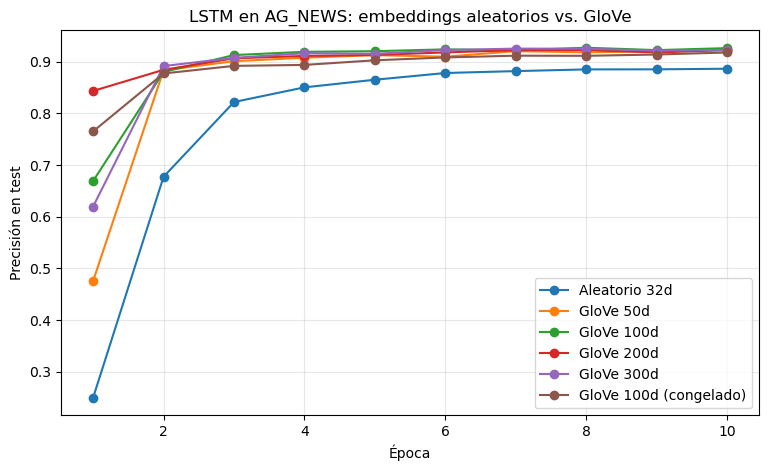

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

summary = pd.DataFrame({
    "Modelo": list(results.keys()),
    "Mejor precisión test": [max(h) for h in results.values()],
    "Precisión final": [h[-1] for h in results.values()],
    "Primera época >80%": [next((i+1 for i, a in enumerate(h) if a > 0.8), None)
                           for h in results.values()],
})
display(summary)

plt.figure(figsize=(9, 5))
for name, h in results.items():
    plt.plot(range(1, len(h)+1), h, marker="o", label=name)
plt.xlabel("Época"); plt.ylabel("Precisión en test")
plt.title("LSTM en AG_NEWS: embeddings aleatorios vs. GloVe")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 10. Conclusiones

*(Rellenar con los resultados obtenidos.)*

- **¿Mejora la precisión con GloVe respecto a embeddings aleatorios?**
- **¿Qué ocurre al cambiar el tamaño (50d, 100d, 200d, 300d)?**
- **Nota:** el modelo usa `lstm_out[:, -1, :]` y el padding va al final, así que en las secuencias cortas la "última salida" corresponde a tokens `<pad>`. Parte de la diferencia en la velocidad de aprendizaje puede venir de ahí y no solo de la calidad de los embeddings.